# Предсказание возрастной категории пользователей интернет-сервисов компании «Йети»

**Задача:** по данным о поведении анонимных пользователей в цифровой среде
(логи посещений сайтов, рекламная активность, характеристики устройств)
построить модель многоклассовой классификации, предсказывающую возрастную
категорию пользователя (0–4).

Это задача **мультиклассовой классификации** с 5 классами,
основная метрика — **F1-macro**, целевой порог ≥ 0.75.

Классы целевой переменной `age_category`:
- 0 — младше 18 лет
- 1 — 18–25 лет
- 2 — 26–40 лет
- 3 — 41–55 лет
- 4 — 56+ лет

## Подготовка среды и библиотек

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, cross_validate, StratifiedKFold, GridSearchCV
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    f1_score, precision_score, recall_score, classification_report,
    ConfusionMatrixDisplay
)
from sklearn.feature_selection import mutual_info_classif

import joblib
import cloudpickle

print('Библиотеки импортированы.')

Библиотеки импортированы.


In [2]:
RANDOM_STATE = 42
TEST_SIZE = 0.25
N_SPLITS = 5
SCORING = {
    'f1_macro': 'f1_macro',
    'precision_macro': 'precision_macro',
    'recall_macro': 'recall_macro',
}

## Исследовательский анализ данных

### Загрузка данных

In [3]:
try:
    users = pd.read_csv('/datasets/ds_s13_users.csv')
    visits = pd.read_csv('/datasets/ds_s13_visits.csv')
    ads = pd.read_csv('/datasets/ads_activity.csv')
    surf = pd.read_csv('/datasets/surf_depth.csv')
    device = pd.read_csv('/datasets/primary_device.csv')
    cloud = pd.read_csv('/datasets/cloud_usage.csv')
    print('Данные загружены из /datasets/')
except FileNotFoundError:
    BASE = 'https://code.s3.yandex.net/datasets/'
    users = pd.read_csv(BASE + 'ds_s13_users.csv')
    visits = pd.read_csv(BASE + 'ds_s13_visits.csv')
    ads = pd.read_csv(BASE + 'ads_activity.csv')
    surf = pd.read_csv(BASE + 'surf_depth.csv')
    device = pd.read_csv(BASE + 'primary_device.csv')
    cloud = pd.read_csv(BASE + 'cloud_usage.csv')
    print('Данные загружены из S3-хранилища.')

for name, df in [('users', users), ('visits', visits), ('ads', ads), ('surf', surf), ('device', device), ('cloud', cloud)]:
    print(f'{name}: {df.shape}')

Данные загружены из S3-хранилища.
users: (5913, 2)
visits: (1065745, 5)
ads: (5826, 2)
surf: (5715, 2)
device: (5669, 2)
cloud: (5680, 2)


### Первичный осмотр таблиц

In [4]:
print('=== users ===')
display(users.head())

=== users ===


,user_id,age_category
0,f545-8c95aefe8d3e5548a689-a5b2fd39,4
1,cb48-5a0d6cde4d86ae10637e-c8ceb6ed,2
2,678b-614cd47d854b9d591db2-000b2e50,0
3,4ac0-dad169100b4a29b20818-b26ae7c5,4
4,f19b-9ac21ca973b41ecfa8c3-6a58191d,0


In [5]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5913 entries, 0 to 5912
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   user_id       5913 non-null   object
 1   age_category  5913 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 92.5+ KB


In [6]:
print('=== visits ===')
display(visits.head())

=== visits ===


,date,daytime,session_id,user_id,website_category
0,2025-11-01,вечер,066e4e02-8c1f-45eb-a50f-178659abe698,0010-5cf8f6b38a7b6c70a021-009dbcda,Category 17
1,2025-11-01,вечер,0bce1749-3376-439c-9a22-f8ffbba00e9a,0010-5cf8f6b38a7b6c70a021-009dbcda,Category 19
2,2025-11-01,вечер,3445d8c4-221d-4d88-bb6a-a2939fe3c610,0010-5cf8f6b38a7b6c70a021-009dbcda,Category 18
3,2025-11-01,вечер,3bf97286-1d91-4aaa-af4a-ed58eceb8cd2,0010-5cf8f6b38a7b6c70a021-009dbcda,Category 20
4,2025-11-01,вечер,40e22712-3cad-410d-a9f0-13bd8f6911c0,0010-5cf8f6b38a7b6c70a021-009dbcda,Category 05


In [7]:
visits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1065745 entries, 0 to 1065744
Data columns (total 5 columns):
 #   Column            Non-Null Count    Dtype 
---  ------            --------------    ----- 
 0   date              1065745 non-null  object
 1   daytime           1065745 non-null  object
 2   session_id        1065745 non-null  object
 3   user_id           1065745 non-null  object
 4   website_category  1065745 non-null  object
dtypes: object(5)
memory usage: 40.7+ MB


In [8]:
print('=== ads_activity ===')
display(ads.head())

=== ads_activity ===


,user_id,ads_activity
0,e318-d8e69c86b543a5fb927c-c36fb6e6,очень часто
1,35cd-a972339dec534f49332c-a8b6d383,редко
2,f7e6-3b29cf9cb7ed4bb00d8f-81534360,очень редко
3,5186-e25a37549e50f45b2b43-178eaabe,умеренно
4,febd-077f277466253ee04ef6-42656680,умеренно


In [9]:
print('=== surf_depth ===')
display(surf.head())

=== surf_depth ===


,user_id,surf_depth
0,f238-0c4c1e787cce311541b7-736925a0,поверхностно
1,9030-1b562ad80182b6dc27f1-ce811740,глубоко
2,22e0-7c6cadcc45e246b8688d-c43c9b23,поверхностно
3,9d7f-a19f10756378940a49b5-5d03e1ef,поверхностно
4,4233-bb5ae4b09827e5497094-1a4956af,глубоко


In [10]:
print('=== primary_device ===')
display(device.head())

=== primary_device ===


,user_id,primary_device
0,d602-ec060db7597a6b8cd4e7-aa625896,смартфон
1,9204-9558455be649d4e77945-b5e25d62,ПК
2,5eea-22babd6a9474b43b9d0b-a39a4cf2,ноутбук
3,c142-0296948e8d08e417de10-2da9523c,смартфон
4,abec-bb4092da51eb2233a928-e44ba074,ПК


In [11]:
print('=== cloud_usage ===')
display(cloud.head())

=== cloud_usage ===


,user_id,cloud_usage
0,a1e4-91c8a52eb855595e653f-298ce305,False
1,db9a-7b8e9e94448b7fcb19b6-4edca15f,False
2,0d55-9ad768879e9b08ca7ff9-843f76c7,True
3,4baa-43285d10a6d3cc969f2a-b21881d1,False
4,b8cd-cbb2411db005115ca64d-32700c62,False


### Пропуски и дубликаты

In [12]:
for name, df in [('users', users), ('visits', visits), ('ads', ads),
                 ('surf', surf), ('device', device), ('cloud', cloud)]:
    nulls = df.isnull().sum()
    dupes = df.duplicated().sum()
    print(f'\n{name}')
    print(f'Дубликатов {dupes}')
    if nulls.sum() > 0:
        print(f'Пропуски:\n{nulls[nulls > 0]}')
    else:
        print('Пропусков нет')


users
Дубликатов 87
Пропусков нет

visits
Дубликатов 15750
Пропусков нет

ads
Дубликатов 233
Пропусков нет

surf
Дубликатов 0
Пропусков нет

device
Дубликатов 0
Пропусков нет

cloud
Дубликатов 0
Пропусков нет


**Вывод:** пропусков ни в одной таблице нет. Дубликаты обнаружены в трёх таблицах:
`users` — 87, `visits` — 15 750, `ads` — 233. В `surf`, `device` и `cloud`
дубликатов нет. Удалим дубликаты

In [13]:
users = users.drop_duplicates()
ads = ads.drop_duplicates()
visits = visits.drop_duplicates()

print(f'users после дедупликации: {users.shape[0]} '
      f'(уникальных user_id: {users["user_id"].nunique()})')
print(f'ads после дедупликации:   {ads.shape[0]}')
print(f'visits после дедупликации: {visits.shape[0]}')

users после дедупликации: 5826 (уникальных user_id: 5826)
ads после дедупликации:   5593
visits после дедупликации: 1049995


**Вывод:** после удаления дубликатов: `users` — 5 826 уникальных пользователей,
`ads` — 5 593 записи, `visits` — 1 049 995 записей. Не все пользователи
присутствуют во всех таблицах — при объединении появятся пропуски.

### Распределение целевой переменной

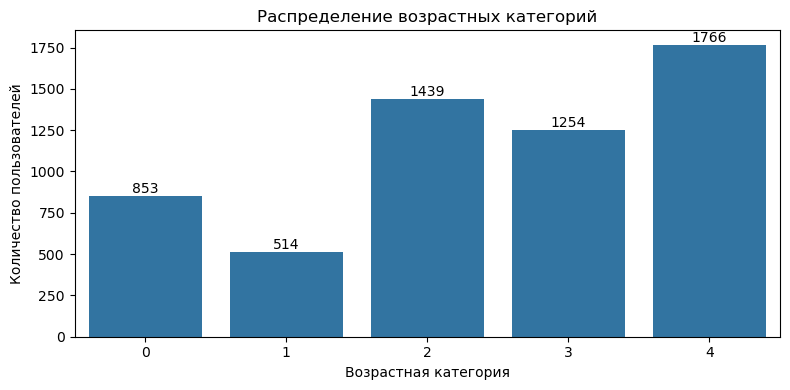

age_category
0     853
1     514
2    1439
3    1254
4    1766
Name: count, dtype: int64


In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
order = sorted(users['age_category'].unique())
sns.countplot(data=users, x='age_category', order=order, ax=ax)
ax.set_title('Распределение возрастных категорий')
ax.set_xlabel('Возрастная категория')
ax.set_ylabel('Количество пользователей')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom')

plt.tight_layout()
plt.show()

print(users['age_category'].value_counts().sort_index())

**Вывод:** классы несбалансированы. Класс 4 (56+) — самый крупный (1 766, ~30 %),
класс 1 (18–25) — самый малочисленный (514, ~9 %). Класс 0 (<18) — 853 (~15 %),
класс 2 (26–40) — 1 439 (~25 %), класс 3 (41–55) — 1 254 (~22 %).
Будем использовать стратификацию при разбиении и F1-macro для корректной оценки
по всем классам, включая редкие.

### Анализ таблицы visits

In [15]:
print('Уникальных пользователей в visits:', visits['user_id'].nunique())
print('Уникальных категорий сайтов:', visits['website_category'].nunique())
print('Период данных:', visits['date'].min(), '—', visits['date'].max())
print('Уникальных дат:', visits['date'].nunique())
print()
print('Категории сайтов:')
print(visits['website_category'].value_counts())

Уникальных пользователей в visits: 5826
Уникальных категорий сайтов: 20
Период данных: 2025-11-01 — 2025-11-14
Уникальных дат: 14

Категории сайтов:
website_category
Category 03    69129
Category 13    67647
Category 05    59720
Category 06    56243
Category 08    55195
Category 19    54568
Category 07    53906
Category 09    53089
Category 01    52401
Category 10    52043
Category 15    51462
Category 04    51072
Category 20    50419
Category 18    50336
Category 12    49940
Category 17    49130
Category 16    45685
Category 14    45525
Category 02    43822
Category 11    38663
Name: count, dtype: int64


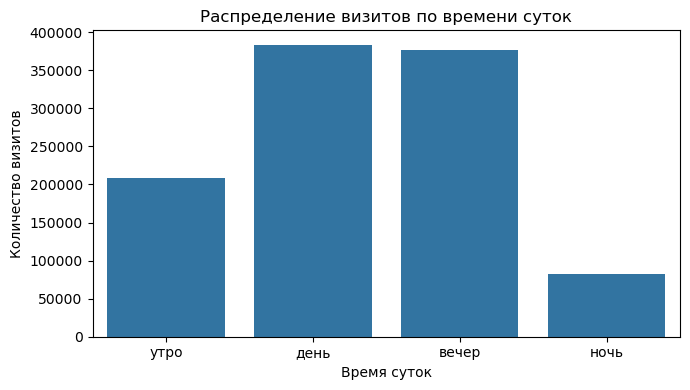

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=visits, x='daytime',
              order=['утро', 'день', 'вечер', 'ночь'], ax=ax)
ax.set_title('Распределение визитов по времени суток')
ax.set_xlabel('Время суток')
ax.set_ylabel('Количество визитов')
plt.tight_layout()
plt.show()

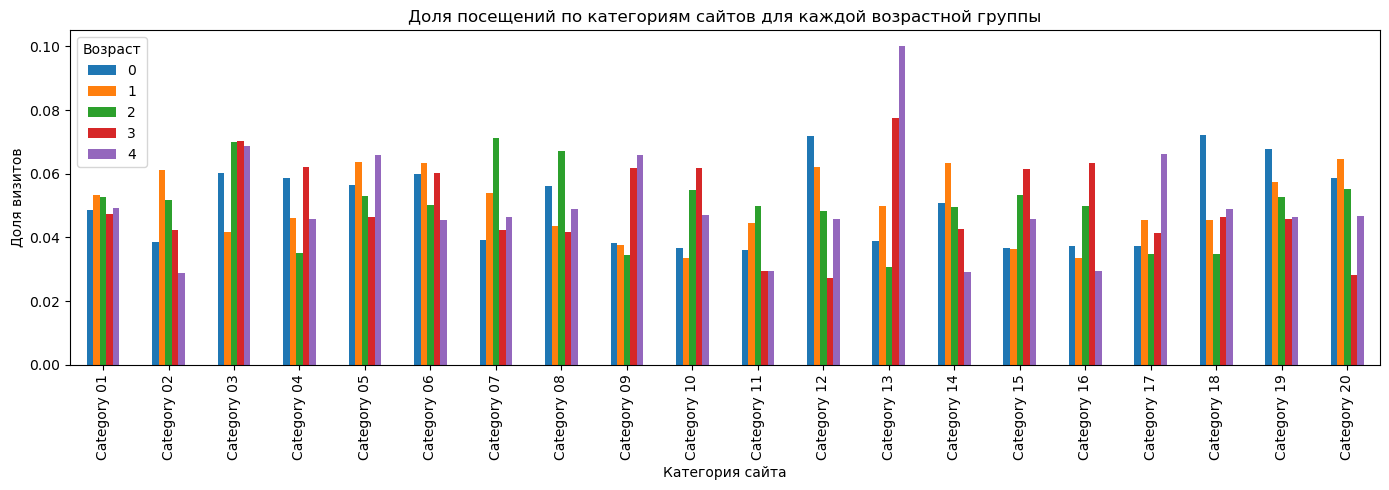

In [17]:
visits_with_age = visits.merge(
    users[['user_id', 'age_category']], on = 'user_id', how = 'inner'
)

cat_age = (visits_with_age
          .groupby(['age_category', 'website_category'])
          .size()
          .reset_index(name ='cnt'))
cat_age_total = cat_age.groupby('age_category')['cnt'].transform('sum')
cat_age['share'] = cat_age['cnt'] / cat_age_total

fig, ax = plt.subplots(figsize=(14, 5))
pivot_viz = cat_age.pivot_table(
    index='website_category', columns='age_category',
    values='share', fill_value=0
)
pivot_viz.plot(kind='bar', ax=ax)
ax.set_title('Доля посещений по категориям сайтов для каждой возрастной группы')
ax.set_xlabel('Категория сайта')
ax.set_ylabel('Доля визитов')
ax.legend(title='Возраст')
plt.tight_layout()
plt.show()

**Вывод по visits:**

- После дедупликации — 1 049 995 визитов 5 826 пользователей за 14 дней (01.11.2025 — 14.11.2025).
- 20 анонимизированных категорий сайтов: самые популярные — Category 03 и Category 13, наименее — Category 11.
- 4 временных слота (утро, день, вечер, ночь).
- У возрастных групп разные «любимые» категории:
  - **<18** — Category 12, 18, 19;
  - **26–40** — Category 07, 08;
  - **41–55** — Category 10, 15, 16;
  - **56+** — Category 13 (10 % всех визитов группы), 09, 17.

Доли категорий и времени суток — основной кандидат в признаки.

### Дополнительные таблицы

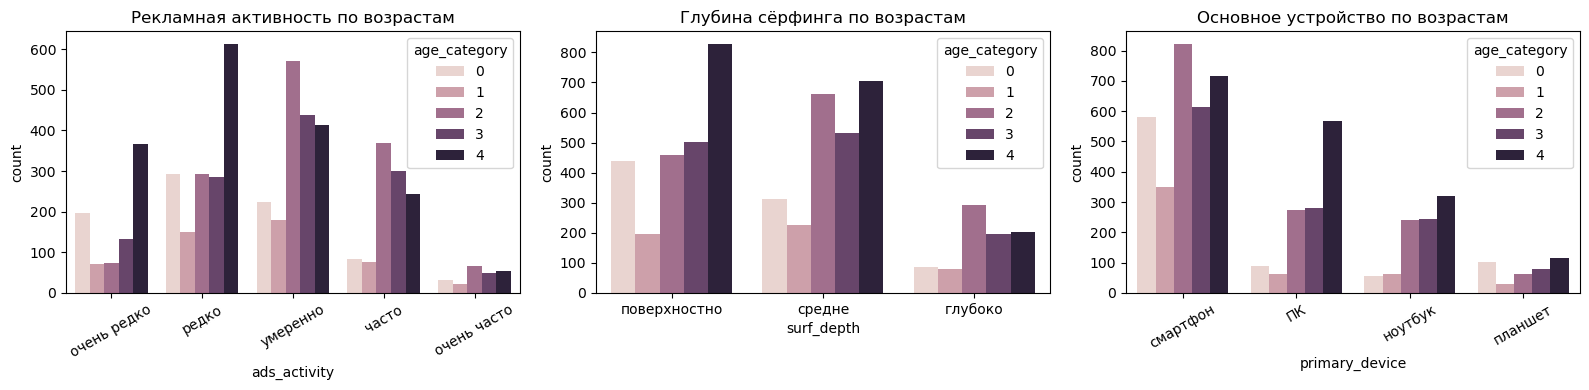

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

ads_merged = ads.merge(users[['user_id', 'age_category']], on='user_id')
sns.countplot(data=ads_merged, x='ads_activity', hue='age_category', ax=axes[0],
              order=['очень редко', 'редко', 'умеренно', 'часто', 'очень часто'])
axes[0].set_title('Рекламная активность по возрастам')
axes[0].tick_params(axis='x', rotation=30)

surf_merged = surf.merge(users[['user_id', 'age_category']], on='user_id')
sns.countplot(data=surf_merged, x='surf_depth', hue='age_category', ax=axes[1],
              order=['поверхностно', 'средне', 'глубоко'])
axes[1].set_title('Глубина сёрфинга по возрастам')

dev_merged = device.merge(users[['user_id', 'age_category']], on='user_id')
sns.countplot(data=dev_merged, x='primary_device', hue='age_category', ax=axes[2])
axes[2].set_title('Основное устройство по возрастам')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**Вывод по дополнительным таблицам** (с поправкой на размер групп):

- **ads_activity:** самые активные по рекламе — 26–40 и 41–55 (у них преобладает «умеренно» и «часто»).
  Группы <18 и 56+ взаимодействуют с рекламой реже всего: у них чаще «редко» и «очень редко».
- **surf_depth:** поверхностный сёрфинг характерен для <18 и 56+ (около половины группы);
  глубокий чаще всего у 26–40.
- **primary_device:** смартфон — основное устройство во всех группах, но у <18 его доля максимальна (~70 %),
  а у 56+ заметно выше доля ПК (~30 %).

Все три признака различаются между возрастными группами и будут полезны для классификации.

## Предобработка данных

### Объединение таблиц и создание признаков

In [19]:
def build_features(users_df, visits_df, ads_df, surf_df, device_df, cloud_df):
    """
    Объединяет все таблицы и создаёт признаковое пространство.
    Если в users_df есть колонка age_category — она сохраняется.
    Внутри выполняется удаление дубликатов и гарантируется фиксированный
    набор выходных признаков (reindex).
    """

    # Удаление дубликатов во входных данных
    users_df = users_df.drop_duplicates()
    visits_df = visits_df.drop_duplicates()
    ads_df = ads_df.drop_duplicates()
    surf_df = surf_df.drop_duplicates()
    device_df = device_df.drop_duplicates()
    cloud_df = cloud_df.drop_duplicates()

    # Фиксированный набор категорий и времени суток
    EXPECTED_CATEGORIES = [f'Category {i:02d}' for i in range(1, 21)]
    EXPECTED_DAYTIMES = ['вечер', 'день', 'ночь', 'утро']

    # 1. Доля посещений по категориям сайтов
    visit_counts = (visits_df
                    .groupby(['user_id', 'website_category'])
                    .size()
                    .reset_index(name='cnt'))
    user_total = visit_counts.groupby('user_id')['cnt'].transform('sum')
    visit_counts['share'] = visit_counts['cnt'] / user_total

    cat_pivot = visit_counts.pivot_table(
        index='user_id', columns='website_category',
        values='share', fill_value=0
    )
    # Гарантируем фиксированный набор столбцов
    cat_pivot = cat_pivot.reindex(columns=EXPECTED_CATEGORIES, fill_value=0)
    cat_pivot.columns = [
        f'cat_share_{c.replace(" ", "_")}' for c in cat_pivot.columns
    ]

    # 2. Доля активности по времени суток
    daytime_counts = (visits_df
                      .groupby(['user_id', 'daytime'])
                      .size()
                      .reset_index(name='cnt'))
    user_total_dt = daytime_counts.groupby('user_id')['cnt'].transform('sum')
    daytime_counts['share'] = daytime_counts['cnt'] / user_total_dt

    dt_pivot = daytime_counts.pivot_table(
        index='user_id', columns='daytime',
        values='share', fill_value=0
    )
    # Гарантируем фиксированный набор столбцов
    dt_pivot = dt_pivot.reindex(columns=EXPECTED_DAYTIMES, fill_value=0)
    dt_pivot.columns = [f'daytime_share_{c}' for c in dt_pivot.columns]

    # 3. Среднее количество сессий в день
    sessions_per_day = (
        visits_df.groupby(['user_id', 'date'])['session_id']
        .nunique()
        .reset_index(name='sessions')
        .groupby('user_id')['sessions']
        .mean()
        .rename('avg_sessions_per_day')
    )

    # 4. Общее число уникальных сессий
    total_sessions = (
        visits_df.groupby('user_id')['session_id']
        .nunique()
        .rename('total_sessions')
    )

    # 5. Количество активных дней
    active_days = (
        visits_df.groupby('user_id')['date']
        .nunique()
        .rename('active_days')
    )

    # 6. Общее число визитов
    total_visits = (
        visits_df.groupby('user_id')
        .size()
        .rename('total_visits')
    )

    # 7. Число уникальных категорий сайтов
    unique_cats = (
        visits_df.groupby('user_id')['website_category']
        .nunique()
        .rename('unique_categories')
    )

    # 8. Наиболее частое время суток — через idxmax по матрице долей
    mode_daytime = dt_pivot.idxmax(axis=1).rename('mode_daytime')
    mode_daytime = mode_daytime.str.replace('daytime_share_', '')

    visit_features = (
        cat_pivot
        .join(dt_pivot)
        .join(sessions_per_day)
        .join(total_sessions)
        .join(active_days)
        .join(total_visits)
        .join(unique_cats)
        .join(mode_daytime)
    )

    keep_cols = ['user_id']
    if 'age_category' in users_df.columns:
        keep_cols.append('age_category')

    df = users_df[keep_cols].copy()
    df = df.merge(visit_features, on='user_id', how='left')
    df = df.merge(ads_df, on='user_id', how='left')
    df = df.merge(surf_df, on='user_id', how='left')
    df = df.merge(device_df, on='user_id', how='left')
    df = df.merge(cloud_df, on='user_id', how='left')

    return df

In [20]:
df = build_features(users, visits, ads, surf, device, cloud)
print(f'Итоговый датафрейм: {df.shape}')
print(f'\nПропуски:\n{df.isnull().sum()[df.isnull().sum() > 0]}')
df.head()

Итоговый датафрейм: (5826, 36)

Пропуски:
ads_activity      233
surf_depth        111
primary_device    157
cloud_usage       146
dtype: int64


,user_id,age_category,cat_share_Category_01,cat_share_Category_02,cat_share_Category_03,cat_share_Category_04,cat_share_Category_05,cat_share_Category_06,cat_share_Category_07,cat_share_Category_08,...,avg_sessions_per_day,total_sessions,active_days,total_visits,unique_categories,mode_daytime,ads_activity,surf_depth,primary_device,cloud_usage
0,f545-8c95aefe8d3e5548a689-a5b2fd39,4,0.064171,0.037433,0.037433,0.058824,0.101604,0.021390,0.000000,0.048128,...,13.357143,187,14,187,19,день,NaN,глубоко,смартфон,False
1,cb48-5a0d6cde4d86ae10637e-c8ceb6ed,2,0.063830,0.042553,0.099291,0.021277,0.056738,0.035461,0.106383,0.106383,...,10.071429,141,14,141,19,вечер,умеренно,средне,смартфон,False
2,678b-614cd47d854b9d591db2-000b2e50,0,0.010000,0.070000,0.000000,0.110000,0.070000,0.130000,0.000000,0.040000,...,7.142857,100,14,100,17,вечер,умеренно,средне,смартфон,False
3,4ac0-dad169100b4a29b20818-b26ae7c5,4,0.080645,0.004032,0.100806,0.028226,0.108871,0.048387,0.028226,0.064516,...,17.714286,248,14,248,19,день,редко,поверхностно,смартфон,True
4,f19b-9ac21ca973b41ecfa8c3-6a58191d,0,0.067227,0.042017,0.092437,0.033613,0.050420,0.008403,0.050420,0.067227,...,8.500000,119,14,119,19,вечер,очень редко,поверхностно,смартфон,True


**Вывод:** итоговый датафрейм — 5 826 строк × 36 столбцов. Пропуски появились
из-за того, что не все пользователи есть во всех таблицах: `ads_activity` — 233,
`surf_depth` — 111, `primary_device` — 157, `cloud_usage` — 146. Заполнение
пропусков выполним внутри пайплайна через `SimpleImputer`, чтобы избежать утечки данных.

### Разделение на обучающую и тестовую выборки

In [21]:
TARGET = 'age_category'

user_labels = df.drop_duplicates('user_id').set_index('user_id')[TARGET]

train_users, test_users = train_test_split(
    user_labels.index,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=user_labels
)

train_df = df[df['user_id'].isin(train_users)].copy()
test_df = df[df['user_id'].isin(test_users)].copy()

X_train = train_df.drop(columns=[TARGET, 'user_id'])
y_train = train_df[TARGET]
X_test = test_df.drop(columns=[TARGET, 'user_id'])
y_test = test_df[TARGET]

print(f'Обучающая выборка: {X_train.shape[0]} строк, '
      f'{len(train_users)} пользователей')
print(f'Тестовая выборка:  {X_test.shape[0]} строк, '
      f'{len(test_users)} пользователей')
print(f'\nРаспределение классов в train:\n'
      f'{y_train.value_counts(normalize=True).sort_index().round(3)}')
print(f'\nРаспределение классов в test:\n'
      f'{y_test.value_counts(normalize=True).sort_index().round(3)}')

Обучающая выборка: 4369 строк, 4369 пользователей
Тестовая выборка:  1457 строк, 1457 пользователей

Распределение классов в train:
age_category
0    0.146
1    0.088
2    0.247
3    0.215
4    0.303
Name: proportion, dtype: float64

Распределение классов в test:
age_category
0    0.146
1    0.088
2    0.247
3    0.216
4    0.303
Name: proportion, dtype: float64


### Типы признаков и пайплайн предобработки

In [22]:
cat_features = ['ads_activity', 'surf_depth', 'primary_device', 'mode_daytime']
bool_features = ['cloud_usage']
num_features = [c for c in X_train.columns
                    if c not in cat_features + bool_features]
print(f'Числовых признаков: {len(num_features)}')
print(f'Категориальных признаков: {len(cat_features)}')
print(f'Бинарных признаков: {len(bool_features)}')

Числовых признаков: 29
Категориальных признаков: 4
Бинарных признаков: 1


In [23]:
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy= 'constant', fill_value = 0)),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy ='constant', fill_value = 'unknown')),
    ('encoder', OneHotEncoder(handle_unknown = 'ignore', sparse_output = False))
])

bool_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=False))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, num_features),
    ('cat', categorical_transformer, cat_features),
    ('bool', bool_transformer, bool_features)
], remainder = 'drop')

print('Пайплайн предобработки создан.')

Пайплайн предобработки создан.


**Вывод по предобработке:** данные разбиты на train (4 369 пользователей, 75 %)
и test (1 457 пользователей, 25 %) с сохранением пропорций классов благодаря
стратификации. Признаковое пространство содержит 29 числовых, 4 категориальных
и 1 бинарный признак. Числовые масштабируются `StandardScaler`, категориальные
кодируются `OneHotEncoder`, пропуски заполняются `SimpleImputer` — всё внутри
пайплайна, утечки данных нет.

## Базовая модель

In [24]:
cv = StratifiedKFold(n_splits = N_SPLITS, shuffle = True, random_state = RANDOM_STATE)

In [25]:
dummy_model = DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE)

dummy_cv = cross_validate(dummy_model, X_train, y_train, cv=cv, scoring=SCORING)

print('=== DummyClassifier (baseline) ===')
print(f'F1 macro CV:        {dummy_cv["test_f1_macro"].mean():.4f} '
      f'± {dummy_cv["test_f1_macro"].std():.4f}')
print(f'Precision macro CV: {dummy_cv["test_precision_macro"].mean():.4f}')
print(f'Recall macro CV:    {dummy_cv["test_recall_macro"].mean():.4f}')

=== DummyClassifier (baseline) ===
F1 macro CV:        0.0930 ± 0.0001
Precision macro CV: 0.0606
Recall macro CV:    0.2000


**Вывод:** DummyClassifier (strategy='most_frequent') даёт F1 macro = 0.0930,
Precision = 0.0606, Recall = 0.2000. Модель всегда предсказывает класс 4 (56+).
Это нижняя граница — любая обученная модель должна значительно превосходить
этот уровень.

## Отбор признаков

Признаки созданы в `build_features`. Оценим их информативность с помощью взаимной информации (Mutual Information).

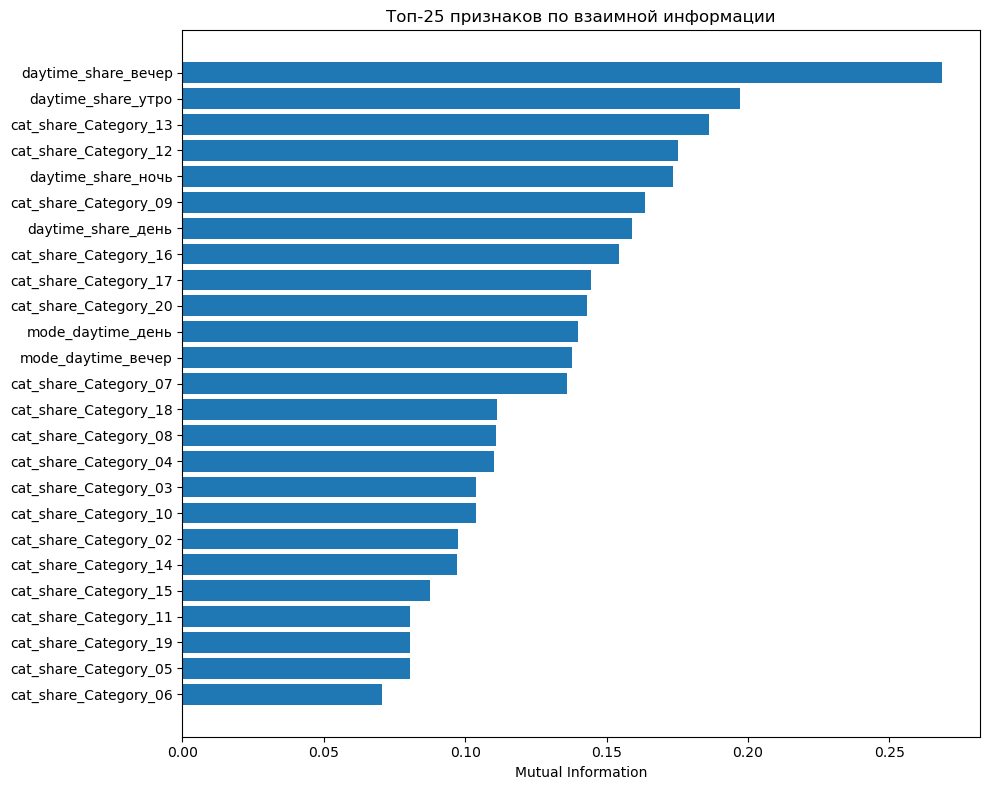

              feature       MI
  daytime_share_вечер 0.268648
   daytime_share_утро 0.197081
cat_share_Category_13 0.186108
cat_share_Category_12 0.175154
   daytime_share_ночь 0.173489
cat_share_Category_09 0.163673
   daytime_share_день 0.159009
cat_share_Category_16 0.154374
cat_share_Category_17 0.144557
cat_share_Category_20 0.143086
    mode_daytime_день 0.139862
   mode_daytime_вечер 0.137647
cat_share_Category_07 0.136176
cat_share_Category_18 0.111155
cat_share_Category_08 0.110916


In [26]:
X_train_transformed = preprocessor.fit_transform(X_train)

ohe_names = (preprocessor
             .named_transformers_['cat']
             .named_steps['encoder']
             .get_feature_names_out(cat_features)
             .tolist())
all_feature_names = num_features + ohe_names + bool_features

mi_scores = mutual_info_classif(
    X_train_transformed, y_train,
    discrete_features=False,
    random_state=RANDOM_STATE
)

mi_df = (pd.DataFrame({'feature': all_feature_names, 'MI': mi_scores})
         .sort_values('MI', ascending=False))

fig, ax = plt.subplots(figsize=(10, 8))
top_n = 25
mi_top = mi_df.head(top_n)
ax.barh(mi_top['feature'][::-1], mi_top['MI'][::-1])
ax.set_title(f'Топ-{top_n} признаков по взаимной информации')
ax.set_xlabel('Mutual Information')
plt.tight_layout()
plt.show()

print(mi_df.head(15).to_string(index=False))

**Вывод:** наиболее информативные признаки — `daytime_share_вечер` (MI = 0.269),
`daytime_share_утро` (0.197), `cat_share_Category_13` (0.186),
`cat_share_Category_12` (0.175), `daytime_share_ночь` (0.173). Распределение
активности по времени суток и доли посещений определённых категорий сайтов —
главные предикторы возрастной группы. Все признаки имеют ненулевой MI,
поэтому оставляем полный набор для обучения


## Подбор гиперпараметров моделей

### LogisticRegression

In [27]:
lr_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        max_iter=1000, random_state=RANDOM_STATE
    )),
])

lr_cv = cross_validate(
    lr_pipe, X_train, y_train, cv=cv, scoring=SCORING
)
print('=== LogisticRegression (default) ===')
print(f'F1 macro CV:        {lr_cv["test_f1_macro"].mean():.4f} '
      f'± {lr_cv["test_f1_macro"].std():.4f}')
print(f'Precision macro CV: '
      f'{lr_cv["test_precision_macro"].mean():.4f}')
print(f'Recall macro CV:    '
      f'{lr_cv["test_recall_macro"].mean():.4f}')

=== LogisticRegression (default) ===
F1 macro CV:        0.8172 ± 0.0064
Precision macro CV: 0.8235
Recall macro CV:    0.8132


In [28]:
lr_param_grid = {
    'model__C': [0.01, 0.1, 1.0, 10.0],
}

lr_grid = GridSearchCV(
    lr_pipe, lr_param_grid, cv=cv, scoring='f1_macro',
    n_jobs=-1, refit=True
)
lr_grid.fit(X_train, y_train)

print('=== LogisticRegression (tuned) ===')
print(f'Лучшие параметры: {lr_grid.best_params_}')
print(f'F1 macro CV:      {lr_grid.best_score_:.4f}')

=== LogisticRegression (tuned) ===
Лучшие параметры: {'model__C': 0.1}
F1 macro CV:      0.8200


### LinearSVC

In [29]:
lsvc_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearSVC(
        max_iter=5000, random_state=RANDOM_STATE, dual='auto'
    )),
])

lsvc_cv = cross_validate(
    lsvc_pipe, X_train, y_train, cv = cv, scoring = SCORING
)
print('=== LinearSVC (default) ===')
print(f'F1 macro CV:        {lsvc_cv["test_f1_macro"].mean():.4f} '
      f'± {lsvc_cv["test_f1_macro"].std():.4f}')
print(f'Precision macro CV: '
      f'{lsvc_cv["test_precision_macro"].mean():.4f}')
print(f'Recall macro CV:    '
      f'{lsvc_cv["test_recall_macro"].mean():.4f}')

=== LinearSVC (default) ===
F1 macro CV:        0.7945 ± 0.0127
Precision macro CV: 0.8191
Recall macro CV:    0.7859


In [30]:
lsvc_param_grid ={'model__C': [0.01, 0.1, 1.0, 10.0]}

lsvc_grid = GridSearchCV(
    lsvc_pipe, lsvc_param_grid, cv = cv, scoring = 'f1_macro',
    n_jobs = -1, refit = True
)
lsvc_grid.fit(X_train, y_train)

print('=== LinearSVC (tuned) ===')
print(f'Лучшие параметры: {lsvc_grid.best_params_}')
print(f'F1 macro CV:      {lsvc_grid.best_score_:.4f}')

=== LinearSVC (tuned) ===
Лучшие параметры: {'model__C': 0.1}
F1 macro CV:      0.7960


### SVC с RBF-ядром

In [31]:
svc_rbf_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', SVC(kernel = 'rbf', random_state = RANDOM_STATE))
])

svc_rbf_cv = cross_validate(svc_rbf_pipe, X_train, y_train, cv = cv, scoring = SCORING)

print('=== SVC (RBF kernel, default) ===')
print(f'F1 macro CV:        {svc_rbf_cv["test_f1_macro"].mean():.4f} '
      f'± {svc_rbf_cv["test_f1_macro"].std():.4f}')
print(f'Precision macro CV: '
      f'{svc_rbf_cv["test_precision_macro"].mean():.4f}')
print(f'Recall macro CV:    '
      f'{svc_rbf_cv["test_recall_macro"].mean():.4f}')

=== SVC (RBF kernel, default) ===
F1 macro CV:        0.8919 ± 0.0102
Precision macro CV: 0.8970
Recall macro CV:    0.8882


In [32]:
svc_param_grid = {
    'model__C': [0.1, 1.0, 10.0],
    'model__gamma': ['scale', 'auto'],
}

svc_grid = GridSearchCV(
    svc_rbf_pipe, svc_param_grid, cv=cv, scoring='f1_macro',
    n_jobs=-1, refit=True
)
svc_grid.fit(X_train, y_train)

print('=== SVC RBF (tuned) ===')
print(f'Лучшие параметры: {svc_grid.best_params_}')
print(f'F1 macro CV:      {svc_grid.best_score_:.4f}')

=== SVC RBF (tuned) ===
Лучшие параметры: {'model__C': 1.0, 'model__gamma': 'scale'}
F1 macro CV:      0.8919


### SVC с полиномиальным ядром

In [33]:
svc_poly_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', SVC(kernel='poly', random_state=RANDOM_STATE)),
])

svc_poly_param_grid = {
    'model__C': [0.1, 1.0, 10.0],
    'model__degree': [2, 3],
}

svc_poly_grid = GridSearchCV(
    svc_poly_pipe, svc_poly_param_grid, cv=cv, scoring='f1_macro',
    n_jobs=-1, refit=True
)
svc_poly_grid.fit(X_train, y_train)

print('=== SVC Poly (tuned) ===')
print(f'Лучшие параметры: {svc_poly_grid.best_params_}')
print(f'F1 macro CV:      {svc_poly_grid.best_score_:.4f}')

=== SVC Poly (tuned) ===
Лучшие параметры: {'model__C': 1.0, 'model__degree': 2}
F1 macro CV:      0.9018


### Сводная таблица результатов

In [34]:
# Precision и Recall для подобранных моделей на тех же фолдах
tuned_cv = {
    name: cross_validate(grid.best_estimator_, X_train, y_train,
                         cv=cv, scoring=SCORING, n_jobs=-1)
    for name, grid in [('lr', lr_grid), ('lsvc', lsvc_grid),
                       ('svc_rbf', svc_grid), ('svc_poly', svc_poly_grid)]
}

results = pd.DataFrame({
    'Модель': [
        'DummyClassifier (baseline)',
        'LogisticRegression (default)',
        'LogisticRegression (tuned)',
        'LinearSVC (default)',
        'LinearSVC (tuned)',
        'SVC RBF (default)',
        'SVC RBF (tuned)',
        'SVC Poly (tuned)',
    ],
    'F1_macro_CV': [
        dummy_cv['test_f1_macro'].mean(),
        lr_cv['test_f1_macro'].mean(),
        lr_grid.best_score_,
        lsvc_cv['test_f1_macro'].mean(),
        lsvc_grid.best_score_,
        svc_rbf_cv['test_f1_macro'].mean(),
        svc_grid.best_score_,
        svc_poly_grid.best_score_,
    ],
    'Precision_macro_CV': [
        dummy_cv['test_precision_macro'].mean(),
        lr_cv['test_precision_macro'].mean(),
        tuned_cv['lr']['test_precision_macro'].mean(),
        lsvc_cv['test_precision_macro'].mean(),
        tuned_cv['lsvc']['test_precision_macro'].mean(),
        svc_rbf_cv['test_precision_macro'].mean(),
        tuned_cv['svc_rbf']['test_precision_macro'].mean(),
        tuned_cv['svc_poly']['test_precision_macro'].mean(),
    ],
    'Recall_macro_CV': [
        dummy_cv['test_recall_macro'].mean(),
        lr_cv['test_recall_macro'].mean(),
        tuned_cv['lr']['test_recall_macro'].mean(),
        lsvc_cv['test_recall_macro'].mean(),
        tuned_cv['lsvc']['test_recall_macro'].mean(),
        svc_rbf_cv['test_recall_macro'].mean(),
        tuned_cv['svc_rbf']['test_recall_macro'].mean(),
        tuned_cv['svc_poly']['test_recall_macro'].mean(),
    ],
}).sort_values('F1_macro_CV', ascending=False)

display(results.reset_index(drop=True))

,Модель,F1_macro_CV,Precision_macro_CV,Recall_macro_CV
0,SVC Poly (tuned),0.901786,0.908711,0.896393
1,SVC RBF (default),0.891907,0.897035,0.888157
2,SVC RBF (tuned),0.891907,0.897035,0.888157
3,LogisticRegression (tuned),0.820049,0.828157,0.814874
4,LogisticRegression (default),0.817191,0.823507,0.813158
5,LinearSVC (tuned),0.795985,0.821025,0.787144
6,LinearSVC (default),0.794537,0.819141,0.785925
7,DummyClassifier (baseline),0.093026,0.060609,0.200000


**Вывод по подбору гиперпараметров:**

- Все модели значительно превосходят baseline (F1 = 0.093).
- Линейные модели: LogisticRegression (C=0.1, lbfgs) — F1 = 0.8200; LinearSVC (C=0.1) — F1 = 0.7960.
- Нелинейные модели существенно лучше: SVC RBF (C=1.0, gamma=scale) — F1 = 0.8919; **SVC Poly (C=1.0, degree=2) — F1 = 0.9018**.
- Лучшая модель — SVC с полиномиальным ядром 2-й степени. Превосходство нелинейных
  моделей говорит о нелинейной связи между признаками и возрастной категорией.

## Оценка лучшей модели на тестовой выборке

In [35]:
grids = {
    'LogisticRegression': lr_grid,
    'LinearSVC': lsvc_grid,
    'SVC_RBF': svc_grid,
    'SVC_POLY': svc_poly_grid
}
best_name = max(grids, key =lambda k: grids[k].best_score_)
best_model = grids[best_name]

print(f'Лучшая модель: {best_name}')
print(f'Лучшие параметры: {best_model.best_params_}')
print(f'F1 macro на кросс-валидации: {best_model.best_score_:.4f}')

Лучшая модель: SVC_POLY
Лучшие параметры: {'model__C': 1.0, 'model__degree': 2}
F1 macro на кросс-валидации: 0.9018


In [36]:
y_pred = best_model.predict(X_test)

test_f1 = f1_score(y_test, y_pred, average ='macro')
test_prec = precision_score(y_test, y_pred, average ='macro')
test_rec = recall_score(y_test, y_pred, average='macro')

print('=== Метрики на тестовой выборке ===')
print(f'F1 macro:        {test_f1:.4f}')
print(f'Precision macro: {test_prec:.4f}')
print(f'Recall macro:    {test_rec:.4f}')
print()
print('Classification Report:')
print(classification_report(
    y_test, y_pred,
    target_names=['<18', '18-25', '26-40', '41-55', '56+']
))

=== Метрики на тестовой выборке ===
F1 macro:        0.8898
Precision macro: 0.8922
Recall macro:    0.8877

Classification Report:
              precision    recall  f1-score   support

         <18       0.91      0.86      0.88       213
       18-25       0.80      0.80      0.80       128
       26-40       0.88      0.89      0.88       360
       41-55       0.93      0.93      0.93       314
         56+       0.93      0.96      0.95       442

    accuracy                           0.91      1457
   macro avg       0.89      0.89      0.89      1457
weighted avg       0.91      0.91      0.91      1457



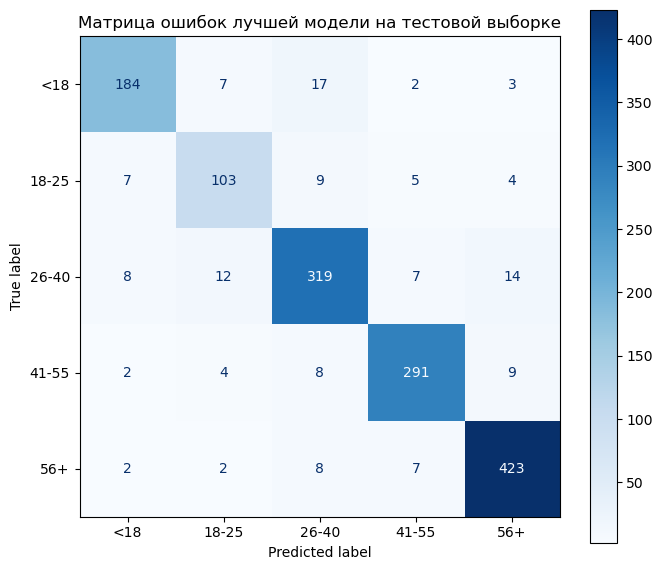

In [37]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['<18', '18-25', '26-40', '41-55', '56+'],
    cmap='Blues', ax=ax
)
ax.set_title('Матрица ошибок лучшей модели на тестовой выборке')
plt.tight_layout()
plt.show()

In [38]:
print(f'\n{"="*50}')
print(f'F1 macro на кросс-валидации: {best_model.best_score_:.4f}')
print(f'F1 macro на тестовой выборке: {test_f1:.4f}')
target_met = (test_f1 >= 0.75) and (best_model.best_score_ >= 0.75)
print(f'Целевой порог >= 0.75 достигнут: '
      f'{"ДА ✓" if target_met else "НЕТ ✗"}')
print(f'Модель {"рекомендуется" if target_met else "НЕ рекомендуется"} '
      f'к внедрению.')


F1 macro на кросс-валидации: 0.9018
F1 macro на тестовой выборке: 0.8898
Целевой порог >= 0.75 достигнут: ДА ✓
Модель рекомендуется к внедрению.


**Вывод по оценке на тесте:**

Лучшая модель — SVC Poly (C=1.0, degree=2).
- F1 macro на кросс-валидации: **0.9018**, на тесте: **0.8898** — переобучения нет.
- Precision macro = 0.8922, Recall macro = 0.8877.
- По классам: лучше всего предсказываются классы 4 (56+, F1 = 0.95) и 3 (41–55, F1 = 0.93),
  хуже всего — класс 1 (18–25, F1 = 0.80), что ожидаемо из-за его малого размера.
- Целевой порог 0.75 **достигнут с запасом**. Модель рекомендуется к внедрению.

## Подготовка артефактов для внедрения

In [39]:
joblib.dump(best_model.best_estimator_, 'best_pipeline.pkl')
print('Пайплайн модели сохранен в best_pipeline.pkl')

with open('build_features.pkl', 'wb') as f:
    cloudpickle.dump(build_features, f)
print('Функция build_features сохранена в build_features.pkl')

Пайплайн модели сохранен в best_pipeline.pkl
Функция build_features сохранена в build_features.pkl


In [40]:
loaded_pipeline = joblib.load('best_pipeline.pkl')
y_pred_loaded = loaded_pipeline.predict(X_test)

assert np.array_equal(y_pred, y_pred_loaded), \
    'ОШИБКА: предсказания не совпадают!'
print('✓ Предсказания до и после загрузки полностью совпадают.')

test_f1_loaded = f1_score(y_test, y_pred_loaded, average='macro')
print(f'F1 macro из загруженной модели: {test_f1_loaded:.4f}')

✓ Предсказания до и после загрузки полностью совпадают.
F1 macro из загруженной модели: 0.8898


In [41]:
with open('build_features.pkl', 'rb') as f:
    loaded_build_features = cloudpickle.load(f)

sample_df = loaded_build_features(
    test_df[['user_id']],
    visits[visits['user_id'].isin(test_users)],
    ads, surf, device, cloud
)
X_sample = sample_df.drop(columns=['user_id'])
y_sample_pred = loaded_pipeline.predict(X_sample)
print(f'✓ Функция build_features загружена и работает корректно.')
print(f'Предсказано {len(y_sample_pred)} значений.')

✓ Функция build_features загружена и работает корректно.
Предсказано 1457 значений.


**Вывод:** артефакты сохранены и проверены:
- `best_pipeline.pkl` — пайплайн (предобработка + SVC Poly), загруженная модель
  выдаёт F1 = 0.8898, полностью совпадает с оригиналом.
- `build_features.pkl` — функция создания признаков, загружена и корректно
  обработала 1 457 пользователей тестовой выборки.
- При внедрении достаточно загрузить оба файла и последовательно вызвать
  `build_features()` → `pipeline.predict()`.

## Выводы о результатах работы

**Задача:** мультиклассовая классификация пользователей по 5 возрастным категориям
(<18, 18–25, 26–40, 41–55, 56+) на основе данных о поведении в интернете.

**Данные:** 5 826 уникальных пользователей, 6 таблиц, ~1 050 000 записей логов
за 14 дней.

**Признаки (34 шт.):**
- 20 долей посещений по категориям сайтов.
- 4 доли активности по времени суток.
- avg_sessions_per_day, total_sessions, active_days, total_visits, unique_categories.
- mode_daytime, ads_activity, surf_depth, primary_device, cloud_usage.

**Результаты:**

| Модель | F1 macro CV |
|--------|-------------|
| DummyClassifier (baseline) | 0.093 |
| LogisticRegression (C=0.1) | 0.820 |
| LinearSVC (C=0.1) | 0.796 |
| SVC RBF (C=1.0, gamma=scale) | 0.892 |
| **SVC Poly (C=1.0, degree=2)** | **0.902** |

**Лучшая модель:** SVC с полиномиальным ядром (degree=2), F1 macro = **0.9018** (CV)
и **0.8898** (тест). Целевой порог 0.75 достигнут с запасом.

**Факторы качества:**
1. Ключевые предикторы — доли активности по времени суток и доли посещений категорий
   сайтов: у каждой возрастной группы свой поведенческий паттерн.
2. Нелинейные модели (SVC Poly, SVC RBF) превосходят линейные на ~0.08–0.11 F1,
   что говорит о нелинейных взаимосвязях в данных.
3. Полиномиальное ядро 2-й степени моделирует парные взаимодействия признаков
   и показало лучший результат.

**Артефакты:** `best_pipeline.pkl` + `build_features.pkl` — готовы к внедрению.